# A/B test: prompting new users to follow 5 accounts

The observational analysis says early follows predict retention. This notebook (1) sizes an experiment to test it causally, (2) simulates running it with the same user model that generated the warehouse, and (3) analyses it: SRM check, two-proportion z-test, confidence intervals, bootstrap and segments.

In [1]:
import json, warnings
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
EXTRACTS, IMAGES = ROOT / "data" / "extracts", ROOT / "docs" / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

# Query the warehouse marts through their Parquet extracts (lock-free while dbt runs)
con = duckdb.connect()
for p in EXTRACTS.glob("*/data.parquet"):
    con.execute(f"create or replace view {p.parent.name} as select * from read_parquet('{p.as_posix()}')")
q = lambda sql: con.execute(sql).df()

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10})

import sys; sys.path.insert(0, str(ROOT))
from generator import config as C
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep
rng = np.random.default_rng(2026)

## 1. Power analysis

Baseline = current day-7 retention from the warehouse. Minimum detectable effect: +2 percentage points.

In [2]:
base = q("select avg(case when d7_retained then 1.0 else 0 end) as p from fct_user_retention where d7_eligible").p[0]
signups_per_day = q("select count(*) / count(distinct signup_date) as n from dim_users").n[0]
rows = []
for mde in [0.01, 0.015, 0.02, 0.03]:
    es = proportion_effectsize(base + mde, base)
    n = NormalIndPower().solve_power(effect_size=es, alpha=0.05, power=0.8, ratio=1)
    rows.append(dict(mde_pp=mde * 100, n_per_arm=int(np.ceil(n)), days_of_signups=np.ceil(2 * n / signups_per_day)))
power = pd.DataFrame(rows)
print(f"baseline d7 = {base:.1%}, ~{signups_per_day:,.0f} signups/day")
power

baseline d7 = 26.9%, ~690 signups/day


,mde_pp,n_per_arm,days_of_signups
0,1.0,31193,91.0
1,1.5,13941,41.0
2,2.0,7885,23.0
3,3.0,3542,11.0


## 2. Simulate the experiment

Users are randomised 50/50. Treatment shows a "follow 5 accounts" prompt, raising first-24h completion from the observed rate to ~60%. Retention then follows the generator's causal model (follows ×2.5 on retention propensity, plus the latent engagement confounder). Some users skip the prompt, so we measure the **intent-to-treat** effect.

In [3]:
N = int(power.loc[power.mde_pp == 2, "n_per_arm"].iloc[0]) * 2
z = rng.normal(size=N)
arm = np.where(rng.random(N) < 0.5, "treatment", "control")
device = rng.choice(C.DEVICES, N, p=C.DEVICE_P)
channel = rng.choice(C.CHANNELS, N, p=C.CHANNEL_P)
sig = lambda x: 1 / (1 + np.exp(-x))
p_follow_ctrl = sig(C.STEP_INTERCEPT[1] + C.STEP_PROPENSITY_WEIGHT * z) * C.P_COMPLETE_WITHIN_24H
p_follow = np.where(arm == "treatment", np.maximum(p_follow_ctrl, 0.60), p_follow_ctrl)
followed = rng.random(N) < p_follow
qprop = C.BASE_D7_RETENTION * np.where(followed, C.STEP_RETENTION_MULT["follow_5_accounts"], 1)
qprop *= pd.Series(channel).map(C.CHANNEL_RETENTION_MULT).values * pd.Series(device).map(C.DEVICE_RETENTION_MULT).values
qprop *= np.exp(C.PROPENSITY_RETENTION_WEIGHT * z)
retained = rng.random(N) < np.clip(qprop, 0, .92)
exp = pd.DataFrame(dict(arm=arm, device=device, channel=channel, followed=followed, d7=retained))
exp.groupby("arm").agg(users=("d7", "size"), follow_24h=("followed", "mean"), d7_retention=("d7", "mean"))

,users,follow_24h,d7_retention
arm,,,
control,7765,0.366774,0.283838
treatment,8005,0.599250,0.331793


## 3. Analyse

**Sample-ratio mismatch** first: if assignment isn't ~50/50 the randomisation is broken and nothing else can be trusted.

In [4]:
counts = exp.arm.value_counts()
srm_p = stats.chisquare(counts.values).pvalue
print(f"SRM check: {dict(counts)}  p = {srm_p:.3f}  ->", "OK" if srm_p > 0.001 else "SAMPLE RATIO MISMATCH")

t, c = exp[exp.arm == "treatment"].d7, exp[exp.arm == "control"].d7
zstat, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
lo, hi = confint_proportions_2indep(t.sum(), len(t), c.sum(), len(c), method="wald")
boot = [rng.choice(t.values, len(t)).mean() - rng.choice(c.values, len(c)).mean() for _ in range(2000)]
summary = pd.Series({
    "control d7": f"{c.mean():.2%}", "treatment d7": f"{t.mean():.2%}",
    "absolute lift": f"{(t.mean() - c.mean()) * 100:+.2f} pp",
    "relative lift": f"{t.mean() / c.mean() - 1:+.1%}",
    "95% CI (Wald)": f"[{lo * 100:+.2f}, {hi * 100:+.2f}] pp",
    "95% CI (bootstrap)": f"[{np.percentile(boot, 2.5) * 100:+.2f}, {np.percentile(boot, 97.5) * 100:+.2f}] pp",
    "z": f"{zstat:.2f}", "p-value": f"{p:.2e}",
})
summary.to_frame("result")

SRM check: {'treatment': np.int64(8005), 'control': np.int64(7765)}  p = 0.056  -> OK


,result
control d7,28.38%
treatment d7,33.18%
absolute lift,+4.80 pp
relative lift,+16.9%
95% CI (Wald),"[+3.36, +6.23] pp"
95% CI (bootstrap),"[+3.35, +6.21] pp"
z,6.52
p-value,7.02e-11


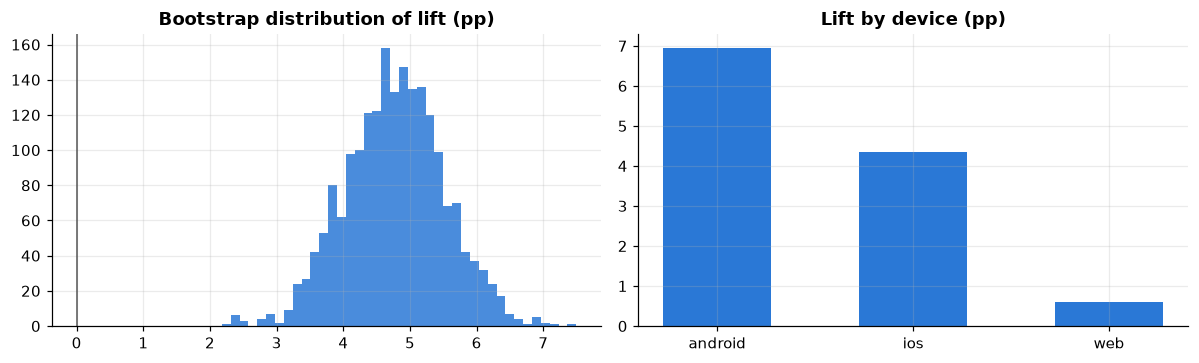

mean              size           lift_pp
arm     control treatment control treatment        
device                                             
android  0.2690    0.3385    3301      3507  6.9457
ios      0.3147    0.3582    3371      3303  4.3416
web      0.2333    0.2393    1093      1195  0.6028

In [5]:
seg = (exp.groupby(["device", "arm"]).d7.agg(["mean", "size"]).unstack("arm"))
seg["lift_pp"] = (seg[("mean", "treatment")] - seg[("mean", "control")]) * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(np.array(boot) * 100, bins=40, color=BLUE, alpha=.85)
ax[0].axvline(0, color="#555", lw=1); ax[0].set_title("Bootstrap distribution of lift (pp)")
ax[1].bar(seg.index, seg.lift_pp, color=BLUE, width=.55); ax[1].set_title("Lift by device (pp)")
plt.tight_layout(); plt.savefig(IMAGES / "ab_test.png", bbox_inches="tight"); plt.show()
seg.round(4)

## 4. Decision

The prompt raises 24h follow completion, and day-7 retention rises with it. The ITT lift is much smaller than the 2.1× observational gap because (a) only the users the prompt *moves* can benefit, and (b) part of the observational gap was confounding from engagement. **Ship if** the CI excludes zero and guardrails (day-1 sessions, unfollow rate, notification opt-outs) don't regress. Note that on real traffic the effect size is unknown before the test; this simulation shows the analysis, not the answer.